# R4b et planéité en 3D

**R4b** (`evomol/newmut/matrix_rules.py`, `r4b_ring`) juge chaque grand cycle (plus de 8 atomes, plus court cycle par
liaison) :
- refus tout de suite s'il contient un carbone s (que des liaisons simples) ;
- sinon, somme des virages autour du cycle (180° − angle intérieur estimé à chaque atome) ; accepté si elle vaut 360°
  à ±40° près (`FLAT_TOLERANCE`), un atome libre pouvant tourner son H vers l'intérieur (−120°) si le cycle a au moins
  14 atomes (`INWARD_H_MIN_RING`).

Aucune géométrie n'est calculée par la règle. Ici, on construit des géométries 3D (RDKit ETKDGv3, puis champ de force
MMFF94) et on mesure la planéité de chaque grand cycle, pour voir si la règle classe bien et si 40° est un bon seuil.

**Lot** : molécules de référence (annulènes, porphine, phtalocyanine, cycloparaphénylènes, cyclophane, éther-couronne…)
et résultats de mutations réelles : toutes les mutations candidates (nouvelles mutations, règles R1-R5) des 120
molécules de `newmut_time`, gardées si elles ont un grand cycle et aucune autre violation que R4b, puis tirées au
hasard par classe.

**Mesures**, pour chaque grand cycle et chaque structure optimisée :

| mesure | ce qu'elle dit |
|---|---|
| `rms_plan` (Å) | écart quadratique moyen des atomes du cycle à leur plan moyen |
| `torsion` (°) | écart moyen des dièdres du cycle à 0° ou 180° |
| `angle_p` (°) | angle moyen entre l'orbitale p de chaque atome du cycle et la normale du plan moyen (0° : orbitales p parallèles, comme le suppose Hückel) |

`_min_E` : structure d'énergie minimale (toutes les structures de la molécule) ; `_mieux` : meilleure valeur sur toutes
les structures, c'est-à-dire « le cycle *peut*-il être plan », ce que dit la règle. `dE_mieux` : énergie de la structure
la plus plane au-dessus du minimum (kcal/mol).

Calcul : `teste/r4b_planeite.py` (`--rapide` pour un essai, résultats dans `resultats/rapide/`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from rdkit.Chem import Draw, rdDepictor

sys.path.insert(0, str(Path.cwd()))
import r4b_planeite as rp  # noqa: E402

DOSSIER = Path("resultats")  # Path("resultats/rapide") : essai --rapide
cycles = pd.read_csv(DOSSIER / "cycles.csv")
molecules = pd.read_csv(DOSSIER / "molecules.csv")
lot = pd.read_csv(DOSSIER / "lot.csv").set_index("nom")
trouvees = pd.read_csv(DOSSIER / "classes_trouvees.csv", index_col=0)

TOLERANCE = 40  # FLAT_TOLERANCE de R4b
VERDICTS = ["acceptée", "refusée angle", "refusée carbone s"]
COULEURS = {"acceptée": "#2a78d6", "refusée angle": "#eb6834", "refusée carbone s": "#1baf7a"}
MARQUEURS = {"acceptée": "o", "refusée angle": "s", "refusée carbone s": "^"}
NOMS = {"rms_plan": "écart au plan moyen (Å, RMS)", "ecart_max": "écart max au plan (Å)",
        "torsion": "écart des dièdres à 0 ou 180° (°)", "angle_p": "angle des orbitales p à la normale (°)"}
QUAND = {"min_E": "structure d'énergie minimale", "mieux": "structure la plus plane"}
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.edgecolor": "#8c8c8c", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "legend.frameon": False,
})
pd.set_option("display.width", 200)


def base(colonne: str) -> str:
    # rms_plan_min_E -> rms_plan
    return colonne.removesuffix("_min_E").removesuffix("_mieux")


def quand(colonne: str) -> str:
    return "mieux" if colonne.endswith("_mieux") else "min_E"


mut = cycles[cycles.source == "mutation"]
ref = cycles[cycles.source == "référence"]
mut_angle = mut[mut.verdict != "refusée carbone s"]  # cycles jugés sur la somme des virages

## 1. Le lot

In [2]:
print("Résultats différents des mutations candidates, avec un grand cycle et R4b seule en jeu :")
display(trouvees.T)
display(pd.crosstab(molecules.source, molecules.classe, margins=True, margins_name="total")
        .rename_axis(index="molécules", columns=None))
display(pd.crosstab(cycles.source, cycles.verdict, margins=True, margins_name="total")
        .rename_axis(index="grands cycles", columns=None))
display(molecules.groupby("source").agg(
    atomes_median=("n_atomes", "median"), isomeres_median=("n_isomeres", "median"),
    structures_median=("n_structures", "median"), sans_structure=("n_structures", lambda s: int((s == 0).sum())),
    non_convergees=("non_convergees", "sum"), minutes=("secondes", lambda s: round(s.sum() / 60, 1))))
print("champ de force :", molecules.champ.value_counts().to_dict())
print("énumération des isomères :", molecules.enumeration.value_counts().to_dict())
print("molécules sans aucune structure 3D :", molecules.loc[molecules.n_structures == 0, "nom"].tolist())

Résultats différents des mutations candidates, avec un grand cycle et R4b seule en jeu :


classe,acceptée,refusée angle,refusée carbone s
molecules_trouvees,47,229,1621


,acceptée,refusée angle,refusée carbone s,total
molécules,,,,
mutation,47,150,150,347
référence,9,7,3,19
total,56,157,153,366


,acceptée,refusée angle,refusée carbone s,total
grands cycles,,,,
mutation,48,159,157,364
référence,9,7,3,19
total,57,166,160,383


,atomes_median,isomeres_median,structures_median,sans_structure,non_convergees,minutes
source,,,,,,
mutation,44.0,16.0,64.0,6,3,716.7
référence,18.0,4.0,32.0,1,0,4.6


champ de force : {'MMFF94': 359}
énumération des isomères : {'normale': 320, 'H explicites': 46}
molécules sans aucune structure 3D : ['cyclo[18]carbone', 'm0156', 'm0160', 'm0169', 'm0180', 'm0189', 'm0235']


## 2. Molécules de référence

`virages` : somme des virages ; `h_dedans` : H tournés vers l'intérieur retenus par la règle ; `ecart` : écart de la
somme à 360° (accepté si ≤ 40°) ; `configs_vues` : configurations cis / trans différentes des doubles liaisons du cycle
obtenues en 3D.

In [3]:
colonnes = ["nom", "taille", "verdict", "virages", "h_dedans", "ecart", "rms_plan_min_E", "rms_plan_mieux",
            "dE_mieux", "torsion_min_E", "angle_p_min_E", "angle_p_mieux", "configs_vues"]
display(ref[colonnes].round(2).set_index("nom"))

,taille,verdict,virages,h_dedans,ecart,rms_plan_min_E,rms_plan_mieux,dE_mieux,torsion_min_E,angle_p_min_E,angle_p_mieux,configs_vues
nom,,,,,,,,,,,,
[10]annulène,10,refusée angle,600.0,0.0,240.0,0.09,0.09,0.00,8.01,9.02,9.02,12.0
[12]annulène,12,refusée angle,720.0,0.0,360.0,0.38,0.24,58.26,37.51,54.60,35.41,20.0
[14]annulène,14,acceptée,840.0,4.0,0.0,0.12,0.12,0.00,10.19,15.67,15.67,29.0
[16]annulène,16,acceptée,960.0,5.0,0.0,0.45,0.28,67.23,15.86,39.35,24.42,57.0
[18]annulène,18,acceptée,1080.0,6.0,0.0,0.11,0.11,0.00,6.66,12.18,12.18,82.0
[20]annulène,20,acceptée,1200.0,7.0,0.0,0.69,0.22,10.74,15.44,47.85,25.31,129.0
[22]annulène,22,acceptée,1320.0,8.0,0.0,0.09,0.09,0.00,4.13,9.29,9.29,229.0
[24]annulène,24,acceptée,1440.0,9.0,0.0,0.72,0.29,10.17,14.45,45.84,24.34,440.0
porphine,16,acceptée,384.0,0.0,24.0,0.00,0.00,0.00,0.00,0.00,0.00,4.0


## 3. À quoi ressemblent les cycles des mutations

Six cycles acceptés et six refusés « angle » tirés au hasard (atomes du grand cycle en couleur). Légende : nom,
écart de la somme des virages à 360° (degrés), écart au plan de la structure d'énergie minimale (Å).

acceptée


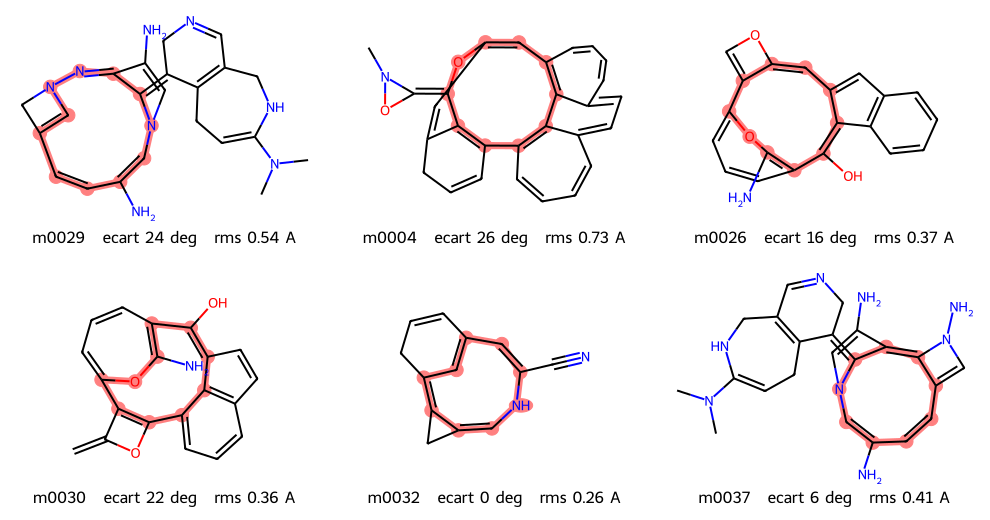

refusée angle


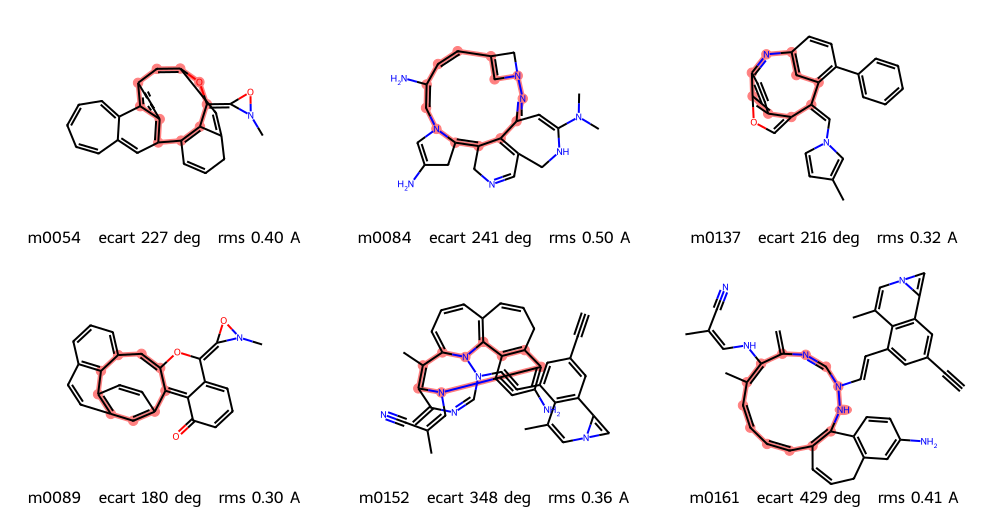

In [4]:
def dessins(data: pd.DataFrame, n: int = 6, graine: int = 0):
    data = data.sample(min(n, len(data)), random_state=graine)
    mols, atomes, legendes = [], [], []
    for row in data.itertuples():
        mol = rp.rdkit_mol(*rp.decode(lot.loc[row.nom, "atomes"], lot.loc[row.nom, "liaisons"]))
        rdDepictor.Compute2DCoords(mol)
        mols.append(mol)
        atomes.append(list(map(int, row.cycle.split())))
        legendes.append(f"{row.nom}   ecart {row.ecart:.0f} deg   rms {row.rms_plan_min_E:.2f} A")  # police RDKit : ASCII
    return Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(330, 260), legends=legendes,
                                highlightAtomLists=atomes)


for verdict in ["acceptée", "refusée angle"]:
    print(verdict)
    display(dessins(mut[mut.verdict == verdict]))

## 4. Planéité selon l'écart à 360°

Cycles jugés sur la somme des virages (acceptés et refusés « angle ») : points pleins, mutations ; points creux,
références. Trait pointillé : tolérance de 40°. Si la règle et la 3D sont d'accord, les cycles à gauche du trait sont
plans (près de 0) et ceux à droite non plans.

,ecart,rms_plan_min_E,rms_plan_mieux,angle_p_min_E,angle_p_mieux
corrélation de rang avec l'écart (mutations),1.0,-0.08,0.16,0.2,0.24


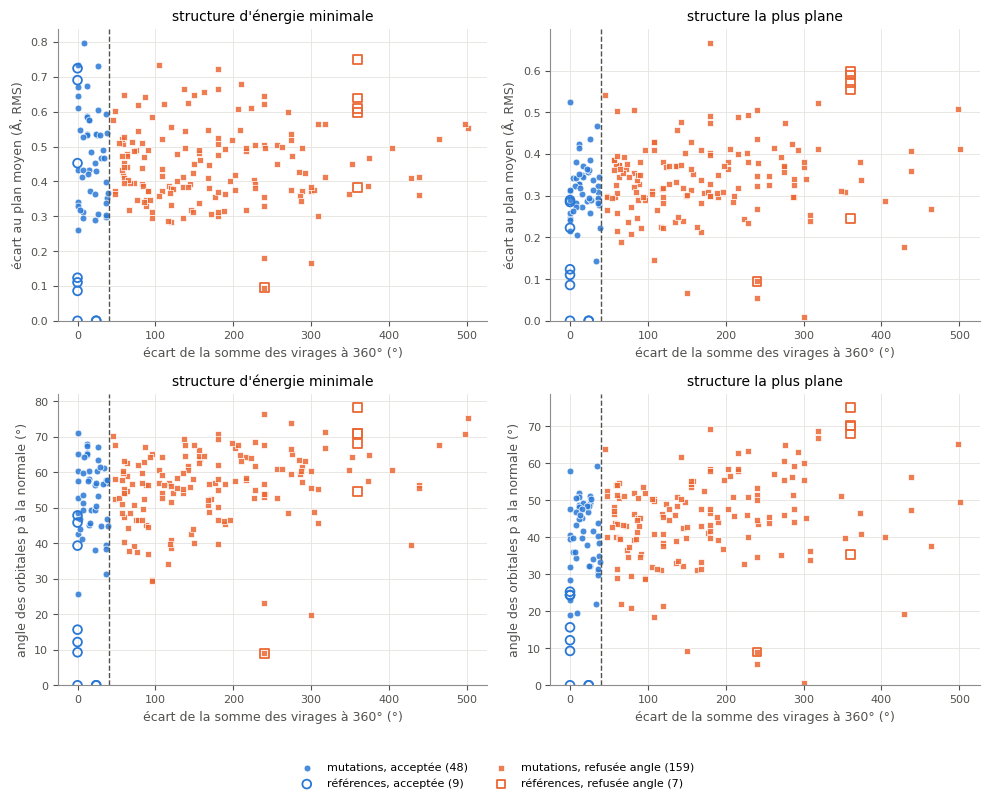

In [5]:
def nuage(colonne: str, ax: plt.Axes) -> None:
    for verdict in ["acceptée", "refusée angle"]:
        sel = mut_angle[mut_angle.verdict == verdict]
        ax.scatter(sel.ecart, sel[colonne], s=24, marker=MARQUEURS[verdict], color=COULEURS[verdict],
                   edgecolors="white", linewidths=0.6, alpha=0.85, label=f"mutations, {verdict} ({len(sel)})")
        sel = ref[ref.verdict == verdict]
        ax.scatter(sel.ecart, sel[colonne], s=40, marker=MARQUEURS[verdict], facecolors="none",
                   edgecolors=COULEURS[verdict], linewidths=1.3, label=f"références, {verdict} ({len(sel)})")
    ax.axvline(TOLERANCE, color="#52514e", lw=1, ls="--")
    ax.set(xlabel="écart de la somme des virages à 360° (°)", ylabel=NOMS[base(colonne)],
           title=QUAND[quand(colonne)])
    ax.set_ylim(bottom=0)


fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ligne, mesure in zip(axes, ["rms_plan", "angle_p"]):
    for ax, q in zip(ligne, ["min_E", "mieux"]):
        nuage(f"{mesure}_{q}", ax)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(DOSSIER / "nuage_ecart.png", dpi=150)
display(mut_angle[["ecart", "rms_plan_min_E", "rms_plan_mieux", "angle_p_min_E", "angle_p_mieux"]]
        .corr(method="spearman").loc[["ecart"]].round(2)
        .rename(index={"ecart": "corrélation de rang avec l'écart (mutations)"}))

## 5. Planéité selon le verdict de R4b

Cycles des mutations, toutes classes, dont les refus « carbone s » (la règle les refuse sans calculer d'angle).
Boîtes : médiane et quartiles ; points : cycles.

,taille,rms_plan_min_E,rms_plan_mieux,torsion_min_E,angle_p_min_E,angle_p_mieux,dE_mieux
médianes,,,,,,,
acceptée,11.0,0.47,0.31,37.67,56.60,41.12,24.82
refusée angle,11.0,0.43,0.34,42.63,56.86,45.50,21.70
refusée carbone s,11.0,0.45,0.31,45.01,54.91,38.62,48.93


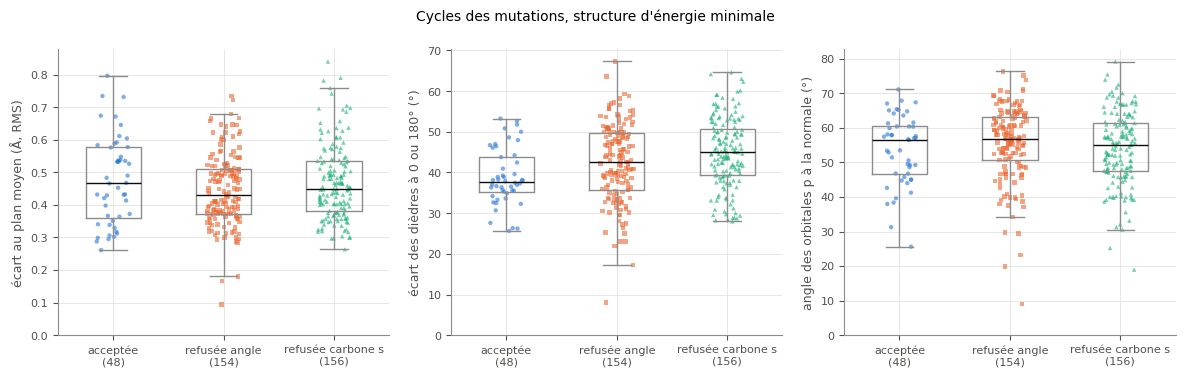

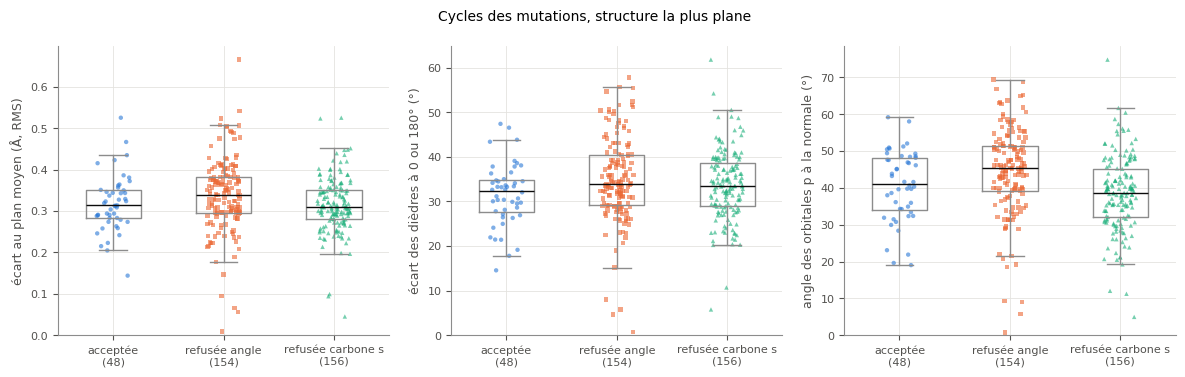

In [6]:
def boites(data: pd.DataFrame, q: str) -> plt.Figure:
    mesures = ["rms_plan", "torsion", "angle_p"]
    fig, axes = plt.subplots(1, len(mesures), figsize=(12, 3.8))
    rng = np.random.default_rng(0)
    for ax, mesure in zip(axes, mesures):
        valeurs = [data.loc[data.verdict == v, f"{mesure}_{q}"].dropna() for v in VERDICTS]
        gris = {"color": "#8c8c8c"}
        ax.boxplot(valeurs, widths=0.5, showfliers=False, medianprops={"color": "#0b0b0b"}, boxprops=gris,
                   whiskerprops=gris, capprops=gris)
        for k, (verdict, vals) in enumerate(zip(VERDICTS, valeurs), start=1):
            ax.scatter(k + rng.uniform(-0.15, 0.15, len(vals)), vals, s=10, color=COULEURS[verdict],
                       marker=MARQUEURS[verdict], alpha=0.6, edgecolors="none")
        ax.set_xticks(range(1, len(VERDICTS) + 1), [f"{v}\n({len(x)})" for v, x in zip(VERDICTS, valeurs)])
        ax.set_ylabel(NOMS[mesure])
        ax.set_ylim(bottom=0)
    fig.suptitle(f"Cycles des mutations, {QUAND[q]}", fontsize=10)
    fig.tight_layout()
    return fig


for q in ["min_E", "mieux"]:
    boites(mut, q).savefig(DOSSIER / f"boites_{q}.png", dpi=150)
display(mut.groupby("verdict")[["taille", "rms_plan_min_E", "rms_plan_mieux", "torsion_min_E", "angle_p_min_E",
                                 "angle_p_mieux", "dE_mieux"]].median().round(2).rename_axis("médianes"))

## 6. R4b sépare-t-elle les cycles plans des autres ?

**Sans seuil** : probabilité qu'un cycle accepté pris au hasard soit plus plan qu'un cycle refusé pris au hasard
(aire sous la courbe ROC). 0,5 : la règle ne sépare pas mieux que le hasard ; 1 : les acceptés sont toujours plus
plans. Entre crochets, intervalle à 95 % par rééchantillonnage (2 000 tirages).

**Avec seuil** : un cycle est dit « plan » si sa mesure est sous un seuil. Il n'y a pas de seuil naturel : plusieurs
sont montrés ; les références donnent l'échelle (section 2).

In [7]:
def proba_plus_plan(a: pd.Series, b: pd.Series) -> float:
    # P(mesure d'un cycle de a < mesure d'un cycle de b), égalités comptées pour moitié
    a, b = np.asarray(a), np.asarray(b)
    if not len(a) or not len(b):
        return np.nan
    rangs = pd.Series(np.concatenate([a, b])).rank().to_numpy()
    return (rangs[len(a):].sum() - len(b) * (len(b) + 1) / 2) / (len(a) * len(b))


def avec_intervalle(a: pd.Series, b: pd.Series, tirages: int = 2000) -> str:
    a, b = a.dropna().to_numpy(), b.dropna().to_numpy()
    if not len(a) or not len(b):
        return "—"
    rng = np.random.default_rng(0)
    boot = [proba_plus_plan(rng.choice(a, len(a)), rng.choice(b, len(b))) for _ in range(tirages)]
    low, high = np.percentile(boot, [2.5, 97.5])
    return f"{proba_plus_plan(a, b):.2f} [{low:.2f} ; {high:.2f}]"


acceptes = mut[mut.verdict == "acceptée"]
lignes = []
for colonne in ["rms_plan_min_E", "rms_plan_mieux", "torsion_min_E", "torsion_mieux", "angle_p_min_E",
                "angle_p_mieux"]:
    lignes.append({"mesure": colonne, **{
        f"acceptée plus plane que {v}": avec_intervalle(acceptes[colonne], mut.loc[mut.verdict == v, colonne])
        for v in ["refusée angle", "refusée carbone s"]}})
display(pd.DataFrame(lignes).set_index("mesure"))


def accord(data: pd.DataFrame, colonne: str, seuil: float) -> pd.DataFrame:
    data = data.dropna(subset=[colonne])
    plan = (data[colonne] <= seuil).map({True: "plan", False: "non plan"})
    table = pd.crosstab(data.verdict, plan).reindex(index=VERDICTS, columns=["plan", "non plan"], fill_value=0)
    table["% plan"] = (100 * table["plan"] / table.sum(axis=1)).round(0)
    return table


for colonne, seuils in [("rms_plan_min_E", (0.1, 0.25, 0.5)), ("rms_plan_mieux", (0.1, 0.25, 0.5)),
                        ("angle_p_min_E", (10, 20, 30)), ("angle_p_mieux", (10, 20, 30))]:
    print(f"{colonne} ≤ seuil (cycles des mutations)")
    display(pd.concat({f"≤ {s}": accord(mut, colonne, s) for s in seuils}, axis=1))

,acceptée plus plane que refusée angle,acceptée plus plane que refusée carbone s
mesure,,
rms_plan_min_E,0.45 [0.34 ; 0.55],0.49 [0.38 ; 0.59]
rms_plan_mieux,0.60 [0.50 ; 0.68],0.50 [0.40 ; 0.60]
torsion_min_E,0.63 [0.55 ; 0.71],0.71 [0.63 ; 0.79]
torsion_mieux,0.61 [0.53 ; 0.69],0.59 [0.50 ; 0.67]
angle_p_min_E,0.56 [0.46 ; 0.65],0.51 [0.41 ; 0.60]
angle_p_mieux,0.62 [0.53 ; 0.70],0.43 [0.34 ; 0.53]


rms_plan_min_E ≤ seuil (cycles des mutations)


≤ 0.1                 ≤ 0.25                 ≤ 0.5                
rms_plan_min_E     plan non plan % plan   plan non plan % plan  plan non plan % plan
verdict                                                                             
acceptée              0       48    0.0      0       48    0.0    27       21   56.0
refusée angle         1      153    1.0      3      151    2.0   109       45   71.0
refusée carbone s     0      156    0.0      0      156    0.0   105       51   67.0

rms_plan_mieux ≤ seuil (cycles des mutations)


≤ 0.1                 ≤ 0.25                 ≤ 0.5                
rms_plan_mieux     plan non plan % plan   plan non plan % plan  plan non plan % plan
verdict                                                                             
acceptée              0       48    0.0      6       42   12.0    47        1   98.0
refusée angle         4      150    3.0     22      132   14.0   147        7   95.0
refusée carbone s     3      153    2.0     19      137   12.0   154        2   99.0

angle_p_min_E ≤ seuil (cycles des mutations)


≤ 10                 ≤ 20                 ≤ 30                
angle_p_min_E     plan non plan % plan plan non plan % plan plan non plan % plan
verdict                                                                         
acceptée             0       48    0.0    0       48    0.0    1       47    2.0
refusée angle        1      153    1.0    2      152    1.0    5      149    3.0
refusée carbone s    0      156    0.0    1      155    1.0    2      154    1.0

angle_p_mieux ≤ seuil (cycles des mutations)


≤ 10                 ≤ 20                 ≤ 30                
angle_p_mieux     plan non plan % plan plan non plan % plan plan non plan % plan
verdict                                                                         
acceptée             0       48    0.0    2       46    4.0    6       42   12.0
refusée angle        4      150    3.0    6      148    4.0   13      141    8.0
refusée carbone s    1      155    1.0    4      152    3.0   27      129   17.0

## 7. La tolérance de 40° est-elle raisonnable ?

Sur les cycles des mutations jugés sur la somme des virages, on fait varier la tolérance et on compare le verdict à
la 3D :
- **faux acceptés** : part des cycles non plans en 3D que la règle accepte ;
- **faux refusés** : part des cycles plans en 3D que la règle refuse ;
- **précision équilibrée** : 1 − (faux acceptés + faux refusés) / 2 (0,5 : pas mieux que le hasard).

**AUC** : probabilité qu'un cycle plan ait un écart à 360° plus petit qu'un cycle non plan (1 : l'écart sépare
parfaitement, 0,5 : au hasard). Elle ne dépend pas de la tolérance. Ces chiffres n'ont de sens que s'il y a des cycles
plans et non plans : ils sont laissés vides avec moins de 5 cycles d'un côté, et seuls ces critères-là sont tracés.

,plans,non plans,AUC,précision à 40°,meilleure précision,tolérances qui l'atteignent
critère « plan »,,,,,,
rms_plan_min_E ≤ 0.1,1,201,NaN,NaN,NaN,NaN
rms_plan_min_E ≤ 0.25,3,199,NaN,NaN,NaN,NaN
rms_plan_min_E ≤ 0.5,136,66,0.43,0.44,0.50,305
rms_plan_mieux ≤ 0.1,4,198,NaN,NaN,NaN,NaN
rms_plan_mieux ≤ 0.25,28,174,0.50,0.49,0.55,170
rms_plan_mieux ≤ 0.5,194,8,0.55,0.56,0.60,"310, 315"
angle_p_min_E ≤ 10,1,201,NaN,NaN,NaN,NaN
angle_p_min_E ≤ 20,2,200,NaN,NaN,NaN,NaN
angle_p_min_E ≤ 30,6,196,0.42,0.46,0.57,0


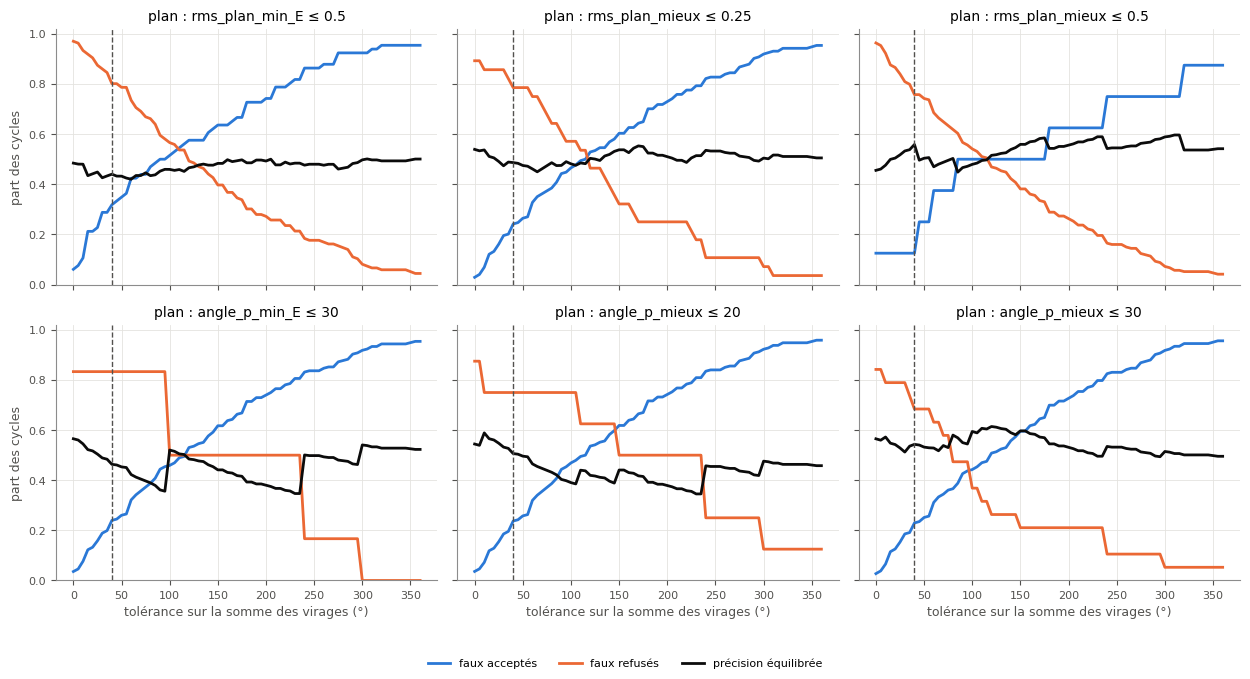

In [8]:
TOLERANCES = np.arange(0, 365, 5)
MINIMUM = 5  # cycles plans et non plans nécessaires


def balayage(data: pd.DataFrame, colonne: str, seuil: float) -> pd.DataFrame:
    data = data.dropna(subset=[colonne])
    plan = data[colonne].to_numpy() <= seuil
    ecart = data.ecart.to_numpy()
    lignes = []
    for t in TOLERANCES:
        accepte = ecart <= t
        fa = (accepte & ~plan).sum() / (~plan).sum()
        fr = (~accepte & plan).sum() / plan.sum()
        lignes.append({"tolérance": t, "faux acceptés": fa, "faux refusés": fr, "précision équilibrée": 1 - (fa + fr) / 2})
    return pd.DataFrame(lignes).set_index("tolérance")


CRITERES = [("rms_plan_min_E", 0.1), ("rms_plan_min_E", 0.25), ("rms_plan_min_E", 0.5),
            ("rms_plan_mieux", 0.1), ("rms_plan_mieux", 0.25), ("rms_plan_mieux", 0.5),
            ("angle_p_min_E", 10), ("angle_p_min_E", 20), ("angle_p_min_E", 30),
            ("angle_p_mieux", 10), ("angle_p_mieux", 20), ("angle_p_mieux", 30)]
resume, traces = [], []
for colonne, seuil in CRITERES:
    data = mut_angle.dropna(subset=[colonne])
    plan = data[colonne] <= seuil
    ligne = {"critère « plan »": f"{colonne} ≤ {seuil}", "plans": int(plan.sum()), "non plans": int((~plan).sum())}
    if plan.sum() >= MINIMUM and (~plan).sum() >= MINIMUM:
        table = balayage(mut_angle, colonne, seuil)
        meilleure = table["précision équilibrée"].max()
        ligne.update({
            "AUC": proba_plus_plan(data.ecart[plan], data.ecart[~plan]),
            "précision à 40°": table.loc[TOLERANCE, "précision équilibrée"], "meilleure précision": meilleure,
            "tolérances qui l'atteignent": ", ".join(map(str, table.index[table["précision équilibrée"] == meilleure])),
        })
        traces.append((colonne, seuil, table))
    resume.append(ligne)
display(pd.DataFrame(resume).set_index("critère « plan »").round(2))

if traces:
    n_col = min(3, len(traces))
    n_lig = -(-len(traces) // n_col)
    fig, axes = plt.subplots(n_lig, n_col, figsize=(4.2 * n_col, 3.4 * n_lig), sharex=True, sharey=True,
                             squeeze=False)
    for ax, (colonne, seuil, table) in zip(axes.flat, traces):
        ax.plot(table.index, table["faux acceptés"], color=COULEURS["acceptée"], lw=2, label="faux acceptés")
        ax.plot(table.index, table["faux refusés"], color=COULEURS["refusée angle"], lw=2, label="faux refusés")
        ax.plot(table.index, table["précision équilibrée"], color="#0b0b0b", lw=2, label="précision équilibrée")
        ax.axvline(TOLERANCE, color="#52514e", lw=1, ls="--")
        ax.set(title=f"plan : {colonne} ≤ {seuil}", ylim=(0, 1.02))
    for ax in list(axes.flat)[len(traces):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("tolérance sur la somme des virages (°)")
    for ax in axes[:, 0]:
        ax.set_ylabel("part des cycles")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    fig.savefig(DOSSIER / "tolerance.png", dpi=150)
else:
    print(f"Aucun critère n'a au moins {MINIMUM} cycles plans et {MINIMUM} non plans : pas de balayage.")

## 8. Le seuil de 14 atomes

Un atome libre ne peut tourner son H vers l'intérieur que si le cycle a au moins 14 atomes. Les cycles de moins de 14
atomes refusés qui passeraient sans ce seuil (`ecart_sans_seuil14` ≤ 40°) sont-ils plans en 3D ?

In [9]:
groupe = np.select(
    [mut_angle.verdict == "acceptée",
     (mut_angle.taille < 14) & (mut_angle.ecart_sans_seuil14 <= TOLERANCE)],
    ["acceptée", "refusée à cause du seuil de 14"], "refusée, autre raison")
display(mut_angle.assign(groupe=groupe)
        .groupby("groupe")[["rms_plan_min_E", "rms_plan_mieux", "angle_p_min_E", "angle_p_mieux"]]
        .agg(["count", "median"]).round(2))
print("Références concernées :")
display(ref[(ref.taille < 14) & (ref.verdict == "refusée angle") & (ref.ecart_sans_seuil14 <= TOLERANCE)]
        [["nom", "taille", "ecart", "ecart_sans_seuil14", "rms_plan_min_E", "rms_plan_mieux", "angle_p_min_E"]]
        .round(2).set_index("nom"))

rms_plan_min_E        rms_plan_mieux        angle_p_min_E        angle_p_mieux       
                                        count median          count median         count median         count median
groupe                                                                                                              
acceptée                                   48   0.47             48   0.31            48  56.60            48  41.12
refusée à cause du seuil de 14             11   0.45             11   0.27            11  48.51            11  34.66
refusée, autre raison                     143   0.42            143   0.34           143  57.12           143  46.11

Références concernées :


,taille,ecart,ecart_sans_seuil14,rms_plan_min_E,rms_plan_mieux,angle_p_min_E
nom,,,,,,
[10]annulène,10,240.0,0.0,0.09,0.09,9.02
[12]annulène,12,360.0,0.0,0.38,0.24,54.60


## 9. Conclusion

Calcul complet du 2026-10-13 : 366 molécules, 383 grands cycles, 92 min sur 8 cœurs. Rapport détaillé :
`rapport_r4b.md`.

- **Références** : R4b donne en général le bon verdict. La porphine, la phtalocyanine, le tridéshydro[12]annulène et
  les [14], [18] et [22]annulènes sont acceptés et plans ou presque (≤ 0,12 Å). Les CPP sont refusés et non plans
  (0,60–0,75 Å, `angle_p` de 68 à 78°). Désaccords : les [16], [20] et [24]annulènes sont acceptés mais non plans
  (0,45–0,72 Å) ; le [10]annulène est refusé alors que MMFF le donne aussi plat que le [18].
- **Cycles des mutations** : presque tous sont non plans, quel que soit le verdict. Médiane de `rms_plan` à
  l'énergie minimale : 0,47 Å (acceptés), 0,43 Å (refusés angle), 0,45 Å (refusés carbone s). Aucun des 48 cycles
  acceptés n'est sous 0,25 Å. La probabilité qu'un accepté soit plus plan qu'un refusé « angle » va de 0,45 à 0,63
  selon la mesure.
- **Tolérance de 40°** : aucune tolérance ne classe mieux que le hasard (AUC 0,41 à 0,59, meilleure précision
  équilibrée ≤ 0,61). 40° n'est ni justifié ni à remplacer à partir de ces données. Le seuil de 14 atomes n'y change
  rien : les 11 cycles refusés seulement à cause de lui sont aussi plans que les acceptés.
- **Cause probable** : les grands cycles des mutations sont des polycycles pontés (une liaison ajoutée par ChangeBondMG
  à travers un système fusionné). Le calcul des virages ne voit pas cette tension.

Limites : MMFF94 seulement, échantillonnage limité, 47 molécules acceptées et très peu de cycles plans dans le lot.

## 10. Descripteurs de pontage : peuvent-ils éliminer les cycles non plans ?

La section 9 montre que les grands cycles non plans des mutations sont surtout des polycycles pontés. On teste ici des
descripteurs de pontage, calculés sur le graphe seul (aucune 3D), en réutilisant les mesures 3D déjà faites.

**Descripteurs de la molécule entière** (code fourni, repris tel quel) :
- `i_overlap` : nombre moyen d'appartenances à un cycle en trop par atome lourd ;
- `bridgehead` : têtes de pont RDKit (`CalcNumBridgeheadAtoms`, cycles qui partagent au moins deux liaisons) ;
- `spiro` : atomes spiro RDKit ; `bridgehead_plus_spiro` : la somme des deux.

**Descripteurs du grand cycle lui-même**, ajoutés pour ne compter que ce qui touche le cycle jugé :
- `i_overlap_cycle` : `i_overlap` limité aux atomes du grand cycle ;
- `jonctions` : atomes du grand cycle qui ont au moins 3 liaisons de cycle (le grand cycle y croise un autre cycle) ;
- `frac_petits` : part des atomes du grand cycle qui sont aussi dans un petit cycle (8 atomes au plus) ;
- `frac_sp3_cycle` : part des atomes du grand cycle à 4 voisins et que des liaisons simples (carbones s, N et O saturés
  comptés de même s'ils ont 4 voisins H compris) ;
- `taille` et `ecart_r4b` (écart de la somme des virages à 360°, mis à 360 pour les refus « carbone s ») pour
  comparer avec R4b.

Critère « plan » principal : `angle_p_mieux` ≤ 30° (les orbitales p *peuvent* être à peu près parallèles, ce qu'il faut
pour Hückel) ; on regarde aussi `rms_plan_mieux` ≤ 0,25 Å. Les critères à l'énergie minimale n'ont presque aucun cycle
plan (3 à 8 sur 358) et ne servent qu'en complément.

In [10]:
from rdkit import Chem
from rdkit.Chem import rdMolDescriptors


# --- code fourni, repris tel quel ---
def i_overlap(mol: Chem.Mol) -> float:
    """Mean excess ring memberships per heavy atom."""
    n_heavy = mol.GetNumHeavyAtoms()
    if n_heavy == 0:
        return 0.0

    ring_info = mol.GetRingInfo()
    memberships = (
        ring_info.NumAtomRings(atom.GetIdx())
        for atom in mol.GetAtoms()
        if atom.GetAtomicNum() > 1
    )
    return sum(max(n_rings - 1, 0) for n_rings in memberships) / n_heavy


def num_bridgehead_atoms(mol: Chem.Mol) -> int:
    """RDKit bridgehead atoms: rings sharing at least two bonds."""
    return rdMolDescriptors.CalcNumBridgeheadAtoms(mol)


def num_spiro_atoms(mol: Chem.Mol) -> int:
    """RDKit spiro atoms: rings sharing exactly one atom."""
    return rdMolDescriptors.CalcNumSpiroAtoms(mol)


def bridgehead_plus_spiro(mol: Chem.Mol) -> int:
    return num_bridgehead_atoms(mol) + num_spiro_atoms(mol)
# --- fin du code fourni ---


def descripteurs(row) -> dict:
    """Descripteurs de la molécule et du grand cycle `row.cycle` (numéros d'atomes de lot.csv)."""
    mol = rp.rdkit_mol(*rp.decode(lot.loc[row.nom, "atomes"], lot.loc[row.nom, "liaisons"]))
    ring_info = mol.GetRingInfo()
    cycle = list(map(int, row.cycle.split()))
    liaisons_cycle = {b.GetIdx() for b in mol.GetBonds() if ring_info.NumBondRings(b.GetIdx())}
    petits = [set(r) for r in ring_info.AtomRings() if len(r) <= 8]

    def n_liaisons_cycle(i: int) -> int:
        return sum(b.GetIdx() in liaisons_cycle for b in mol.GetAtomWithIdx(i).GetBonds())

    def sature(i: int) -> bool:
        atome = mol.GetAtomWithIdx(i)
        return (all(b.GetBondTypeAsDouble() == 1 for b in atome.GetBonds())
                and atome.GetDegree() + atome.GetTotalNumHs() == 4)

    return {
        "i_overlap": i_overlap(mol), "bridgehead": num_bridgehead_atoms(mol), "spiro": num_spiro_atoms(mol),
        "bridgehead_plus_spiro": bridgehead_plus_spiro(mol),
        "i_overlap_cycle": sum(max(ring_info.NumAtomRings(i) - 1, 0) for i in cycle) / len(cycle),
        "jonctions": sum(n_liaisons_cycle(i) >= 3 for i in cycle),
        "frac_petits": sum(any(i in r for r in petits) for i in cycle) / len(cycle),
        "frac_sp3_cycle": sum(map(sature, cycle)) / len(cycle),
    }


cyc = pd.concat([cycles, cycles.apply(descripteurs, axis=1, result_type="expand")], axis=1)
cyc["ecart_r4b"] = cyc.ecart.fillna(360)  # refus « carbone s » : écart non calculé
DESCRIPTEURS = ["bridgehead", "i_overlap", "spiro", "bridgehead_plus_spiro", "i_overlap_cycle", "jonctions",
                "frac_petits", "frac_sp3_cycle", "taille", "ecart_r4b"]
mut_d = cyc[cyc.source == "mutation"].dropna(subset=["angle_p_mieux"])  # cycles des mutations avec une structure 3D
CRITERES_PLAN = {"angle_p_mieux ≤ 30": mut_d.angle_p_mieux <= 30, "rms_plan_mieux ≤ 0.25": mut_d.rms_plan_mieux <= 0.25,
                 "angle_p_min_E ≤ 30": mut_d.angle_p_min_E <= 30, "rms_plan_min_E ≤ 0.5": mut_d.rms_plan_min_E <= 0.5}
print(len(mut_d), "cycles des mutations ;", {k: f"{int(v.sum())} plans" for k, v in CRITERES_PLAN.items()})
print("cycles des mutations avec spiro non nul :", int((mut_d.spiro > 0).sum()))
display(mut_d.groupby("verdict")[DESCRIPTEURS].median().round(2).rename_axis("médianes"))

358 cycles des mutations ; {'angle_p_mieux ≤ 30': '46 plans', 'rms_plan_mieux ≤ 0.25': '47 plans', 'angle_p_min_E ≤ 30': '8 plans', 'rms_plan_min_E ≤ 0.5': '241 plans'}
cycles des mutations avec spiro non nul : 0


,bridgehead,i_overlap,spiro,bridgehead_plus_spiro,i_overlap_cycle,jonctions,frac_petits,frac_sp3_cycle,taille,ecart_r4b
médianes,,,,,,,,,,
acceptée,3.5,0.46,0.0,3.5,1.19,6.0,0.7,0.00,11.0,15.0
refusée angle,6.0,0.53,0.0,6.0,1.42,7.0,0.8,0.00,11.0,156.0
refusée carbone s,4.0,0.40,0.0,4.0,1.00,6.0,0.7,0.18,11.0,360.0


### 10.1 Références

Les descripteurs ne voient que les ponts et les fusions : ils devraient refuser les CPP et le paracyclophane, mais ne
rien dire des annulènes, de l'éther-couronne ni du cyclododécane.

In [11]:
display(cyc[cyc.source == "référence"].set_index("nom")[
    ["verdict", "rms_plan_min_E", "angle_p_min_E", "angle_p_mieux"] + DESCRIPTEURS[:-2]].round(2))

,verdict,rms_plan_min_E,angle_p_min_E,angle_p_mieux,bridgehead,i_overlap,spiro,bridgehead_plus_spiro,i_overlap_cycle,jonctions,frac_petits,frac_sp3_cycle
nom,,,,,,,,,,,,
[10]annulène,refusée angle,0.09,9.02,9.02,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00
[12]annulène,refusée angle,0.38,54.60,35.41,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00
[14]annulène,acceptée,0.12,15.67,15.67,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00
[16]annulène,acceptée,0.45,39.35,24.42,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00
[18]annulène,acceptée,0.11,12.18,12.18,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00
[20]annulène,acceptée,0.69,47.85,25.31,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00
[22]annulène,acceptée,0.09,9.29,9.29,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00
[24]annulène,acceptée,0.72,45.84,24.34,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00
porphine,acceptée,0.00,0.00,0.00,8.0,0.50,0.0,8.0,0.75,8.0,0.75,0.00


### 10.2 Chaque descripteur seul

Probabilité qu'un cycle plan ait une valeur plus petite qu'un cycle non plan (1 : la valeur sépare parfaitement, petite
pour les plans ; 0,5 : au hasard ; sous 0,5 : les cycles plans ont plutôt des valeurs *plus grandes*). Entre crochets,
intervalle à 95 % par rééchantillonnage. Cycles des mutations.

In [12]:
table = pd.DataFrame({
    f"{critere} ({int(plan.sum())} plans)": {d: avec_intervalle(mut_d.loc[plan, d], mut_d.loc[~plan, d])
                                              for d in DESCRIPTEURS}
    for critere, plan in CRITERES_PLAN.items()})
display(table.rename_axis("P(plan < non plan)"))
display(mut_d[DESCRIPTEURS + ["rms_plan_mieux", "angle_p_mieux", "angle_p_min_E"]].corr("spearman")
        .loc[DESCRIPTEURS, ["rms_plan_mieux", "angle_p_mieux", "angle_p_min_E"]].round(2)
        .rename_axis("corrélation de rang"))

,angle_p_mieux ≤ 30 (46 plans),rms_plan_mieux ≤ 0.25 (47 plans),angle_p_min_E ≤ 30 (8 plans),rms_plan_min_E ≤ 0.5 (241 plans)
P(plan < non plan),,,,
bridgehead,0.82 [0.75 ; 0.88],0.75 [0.68 ; 0.82],0.94 [0.90 ; 0.97],0.49 [0.43 ; 0.55]
i_overlap,0.67 [0.59 ; 0.75],0.71 [0.64 ; 0.78],0.72 [0.51 ; 0.91],0.60 [0.54 ; 0.66]
spiro,0.50 [0.50 ; 0.50],0.50 [0.50 ; 0.50],0.50 [0.50 ; 0.50],0.50 [0.50 ; 0.50]
bridgehead_plus_spiro,0.82 [0.75 ; 0.88],0.75 [0.68 ; 0.82],0.94 [0.90 ; 0.97],0.49 [0.43 ; 0.55]
i_overlap_cycle,0.72 [0.65 ; 0.80],0.70 [0.62 ; 0.78],0.88 [0.77 ; 0.97],0.58 [0.52 ; 0.64]
jonctions,0.70 [0.61 ; 0.78],0.74 [0.67 ; 0.82],0.77 [0.56 ; 0.94],0.49 [0.43 ; 0.56]
frac_petits,0.76 [0.68 ; 0.83],0.69 [0.60 ; 0.77],0.82 [0.62 ; 0.96],0.48 [0.42 ; 0.55]
frac_sp3_cycle,0.38 [0.29 ; 0.46],0.50 [0.42 ; 0.58],0.59 [0.40 ; 0.73],0.49 [0.44 ; 0.55]
taille,0.58 [0.50 ; 0.66],0.63 [0.55 ; 0.71],0.76 [0.66 ; 0.85],0.62 [0.56 ; 0.68]


,rms_plan_mieux,angle_p_mieux,angle_p_min_E
corrélation de rang,,,
bridgehead,0.46,0.60,0.47
i_overlap,0.50,0.41,0.30
spiro,NaN,NaN,NaN
bridgehead_plus_spiro,0.46,0.60,0.47
i_overlap_cycle,0.50,0.47,0.43
jonctions,0.32,0.27,0.10
frac_petits,0.44,0.55,0.41
frac_sp3_cycle,-0.15,-0.30,-0.08
taille,0.17,-0.01,-0.02


### 10.3 Un seuil sur un descripteur

Règle « plan si descripteur ≤ seuil ». Gardés : cycles que la règle laisse passer. Précision équilibrée :
1 − (faux acceptés + faux refusés) / 2. La ligne R4b rappelle le verdict actuel.

In [13]:
def bilan_filtre(garde: pd.Series, plan: pd.Series) -> dict:
    fa = (garde & ~plan).sum() / (~plan).sum()
    fr = (~garde & plan).sum() / plan.sum()
    return {"gardés": int(garde.sum()), "plans gardés": f"{int((garde & plan).sum())}/{int(plan.sum())}",
            "non plans éliminés": f"{int((~garde & ~plan).sum())}/{int((~plan).sum())}",
            "précision équilibrée": round(1 - (fa + fr) / 2, 2)}


for critere in ["angle_p_mieux ≤ 30", "rms_plan_mieux ≤ 0.25"]:
    plan = CRITERES_PLAN[critere]
    lignes = {"R4b (acceptée)": bilan_filtre(mut_d.verdict == "acceptée", plan)}
    for d, seuils in [("bridgehead", [0, 2, 3, 4, 6]), ("jonctions", [0, 2, 4, 6, 8]),
                      ("i_overlap", [0.2, 0.3, 0.4, 0.5]), ("frac_petits", [0.4, 0.6, 0.8])]:
        for s in seuils:
            lignes[f"{d} ≤ {s}"] = bilan_filtre(mut_d[d] <= s, plan)
    print(critere)
    display(pd.DataFrame(lignes).T)

angle_p_mieux ≤ 30


,gardés,plans gardés,non plans éliminés,précision équilibrée
R4b (acceptée),48,6/46,270/312,0.5
bridgehead ≤ 0,34,19/46,297/312,0.68
bridgehead ≤ 2,110,36/46,238/312,0.77
bridgehead ≤ 3,115,37/46,234/312,0.78
bridgehead ≤ 4,214,42/46,140/312,0.68
bridgehead ≤ 6,305,44/46,51/312,0.56
jonctions ≤ 0,5,3/46,310/312,0.53
jonctions ≤ 2,15,9/46,306/312,0.59
jonctions ≤ 4,57,19/46,274/312,0.65
jonctions ≤ 6,190,35/46,157/312,0.63


rms_plan_mieux ≤ 0.25


,gardés,plans gardés,non plans éliminés,précision équilibrée
R4b (acceptée),48,6/47,269/311,0.5
bridgehead ≤ 0,34,15/47,292/311,0.63
bridgehead ≤ 2,110,30/47,231/311,0.69
bridgehead ≤ 3,115,30/47,226/311,0.68
bridgehead ≤ 4,214,41/47,138/311,0.66
bridgehead ≤ 6,305,46/47,52/311,0.57
jonctions ≤ 0,5,3/47,309/311,0.53
jonctions ≤ 2,15,8/47,304/311,0.57
jonctions ≤ 4,57,20/47,274/311,0.65
jonctions ≤ 6,190,38/47,159/311,0.66


### 10.4 Combiner les descripteurs

**Régression logistique** sur 1, 2 ou 3 descripteurs (variables centrées réduites) : aire sous la courbe ROC en
validation croisée (5 blocs × 10 répétitions), donc mesurée sur des cycles que le modèle n'a pas vus. On montre les
meilleures combinaisons et, pour comparer, chaque descripteur seul et tous ensemble. `spiro` et
`bridgehead_plus_spiro` sont laissés de côté (identiques à 0 et à `bridgehead` sur ces cycles).

In [14]:
from itertools import combinations

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

A_COMBINER = ["bridgehead", "i_overlap", "i_overlap_cycle", "jonctions", "frac_petits", "frac_sp3_cycle", "taille",
              "ecart_r4b"]
VALIDATION = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)


def auc_cv(colonnes: list[str], plan: pd.Series) -> float:
    modele = make_pipeline(StandardScaler(), LogisticRegression())
    return cross_val_score(modele, mut_d[list(colonnes)], plan, cv=VALIDATION, scoring="roc_auc").mean()


combis = {}
for critere in ["angle_p_mieux ≤ 30", "rms_plan_mieux ≤ 0.25"]:
    plan = CRITERES_PLAN[critere]
    scores = {c: auc_cv(c, plan) for k in (1, 2, 3) for c in combinations(A_COMBINER, k)}
    scores[tuple(A_COMBINER)] = auc_cv(A_COMBINER, plan)
    combis[critere] = pd.Series({" + ".join(c): v for c, v in scores.items()})
    print(f"{critere} : meilleures combinaisons (AUC en validation croisée)")
    display(combis[critere].sort_values(ascending=False).head(10).round(3).to_frame("AUC"))
    seuls = combis[critere][A_COMBINER].sort_values(ascending=False)
    print("seuls : " + ", ".join(f"{d} {v:.3f}" for d, v in seuls.items())
          + f" ; tous ensemble : {combis[critere][' + '.join(A_COMBINER)]:.3f}")

angle_p_mieux ≤ 30 : meilleures combinaisons (AUC en validation croisée)


,AUC
bridgehead + jonctions + frac_sp3_cycle,0.847
bridgehead + frac_sp3_cycle + ecart_r4b,0.840
bridgehead + frac_petits + frac_sp3_cycle,0.838
bridgehead + frac_sp3_cycle,0.838
bridgehead + jonctions,0.837
bridgehead + frac_sp3_cycle + taille,0.837
bridgehead + i_overlap + i_overlap_cycle + jonctions + frac_petits + frac_sp3_cycle + taille + ecart_r4b,0.836
bridgehead + i_overlap_cycle + jonctions,0.835
bridgehead + i_overlap + jonctions,0.835
bridgehead + i_overlap_cycle + frac_sp3_cycle,0.834


seuls : bridgehead 0.822, frac_petits 0.760, i_overlap_cycle 0.724, jonctions 0.699, i_overlap 0.668, frac_sp3_cycle 0.624, taille 0.584, ecart_r4b 0.549 ; tous ensemble : 0.836


rms_plan_mieux ≤ 0.25 : meilleures combinaisons (AUC en validation croisée)


,AUC
bridgehead + i_overlap + jonctions,0.781
bridgehead + jonctions + frac_petits,0.775
bridgehead + jonctions + ecart_r4b,0.773
i_overlap + jonctions + ecart_r4b,0.773
bridgehead + jonctions,0.773
i_overlap + jonctions,0.771
bridgehead + i_overlap + i_overlap_cycle + jonctions + frac_petits + frac_sp3_cycle + taille + ecart_r4b,0.771
bridgehead + jonctions + frac_sp3_cycle,0.770
bridgehead + jonctions + taille,0.770
bridgehead + i_overlap_cycle + jonctions,0.769


seuls : bridgehead 0.747, jonctions 0.743, i_overlap 0.705, i_overlap_cycle 0.697, frac_petits 0.691, taille 0.633, ecart_r4b 0.480, frac_sp3_cycle 0.433 ; tous ensemble : 0.771


**Règle à deux seuils**, utilisable telle quelle dans une mutation : « plan si `d1` ≤ `s1` et `d2` ≤ `s2` » (pour un
descripteur dont les grandes valeurs vont avec les cycles plans, comme `frac_sp3_cycle`, la condition est ≥). Les
seuils sont choisis pour maximiser la précision équilibrée. Pour ne pas se tromper sur leur qualité, ils sont choisis
sur 4/5 des cycles et évalués sur le 1/5 restant (validation croisée, mêmes blocs). À comparer à la même procédure avec
un seul descripteur.

In [15]:
def precision_equilibree(garde: np.ndarray, plan: np.ndarray) -> float:
    return 1 - ((garde & ~plan).sum() / max((~plan).sum(), 1) + (~garde & plan).sum() / max(plan.sum(), 1)) / 2


def sens(d: str, plan: pd.Series) -> int:
    # +1 : petites valeurs = plan ; -1 : grandes valeurs = plan
    return 1 if proba_plus_plan(mut_d.loc[plan, d], mut_d.loc[~plan, d]) >= 0.5 else -1


def meilleure_regle(x: pd.DataFrame, plan: np.ndarray, colonnes: tuple[str, ...]) -> tuple[tuple, float]:
    """Seuils (un par colonne, valeurs déjà orientées : garder si ≤) maximisant la précision équilibrée."""
    candidats = [np.unique(x[c]) for c in colonnes]
    meilleur, score = None, -1
    for seuils in np.array(np.meshgrid(*candidats)).reshape(len(colonnes), -1).T:
        garde = np.all([x[c].to_numpy() <= s for c, s in zip(colonnes, seuils)], axis=0)
        p = precision_equilibree(garde, plan)
        if p > score:
            meilleur, score = tuple(seuils), p
    return meilleur, score


def regle_cv(colonnes: tuple[str, ...], plan: pd.Series) -> tuple[float, tuple, float]:
    x = mut_d[list(colonnes)] * [sens(c, plan) for c in colonnes]
    y = plan.to_numpy()
    tests = []
    for app, test in VALIDATION.split(x, y):
        seuils, _ = meilleure_regle(x.iloc[app], y[app], colonnes)
        garde = np.all([x[c].to_numpy()[test] <= s for c, s in zip(colonnes, seuils)], axis=0)
        tests.append(precision_equilibree(garde, y[test]))
    seuils, score = meilleure_regle(x, y, colonnes)  # règle finale, sur tous les cycles
    return np.mean(tests), tuple(s * sens(c, plan) for c, s in zip(colonnes, seuils)), score


def ecrire(colonnes, seuils, plan) -> str:
    return " et ".join(f"{c} {'≤' if sens(c, plan) > 0 else '≥'} {s:.3g}" for c, s in zip(colonnes, seuils))


REGLES_A_ESSAYER = ["bridgehead", "i_overlap", "i_overlap_cycle", "jonctions", "frac_petits", "frac_sp3_cycle",
                    "taille"]
regles = {}
for critere in ["angle_p_mieux ≤ 30", "rms_plan_mieux ≤ 0.25"]:
    plan = CRITERES_PLAN[critere]
    lignes = []
    for k in (1, 2):
        for colonnes in combinations(REGLES_A_ESSAYER, k):
            cv, seuils, score = regle_cv(colonnes, plan)
            lignes.append({"règle (seuils choisis sur tous les cycles)": ecrire(colonnes, seuils, plan),
                           "précision équilibrée, validation croisée": round(cv, 3),
                           "précision équilibrée, sur tous les cycles": round(score, 3),
                           "colonnes": colonnes, "seuils": seuils})
    regles[critere] = pd.DataFrame(lignes).sort_values("précision équilibrée, validation croisée", ascending=False)
    print(critere, "(R4b actuelle : 0,50)")
    display(regles[critere].drop(columns=["colonnes", "seuils"]).head(10).set_index(
        "règle (seuils choisis sur tous les cycles)"))

angle_p_mieux ≤ 30 (R4b actuelle : 0,50)


,"précision équilibrée, validation croisée","précision équilibrée, sur tous les cycles"
règle (seuils choisis sur tous les cycles),,
bridgehead ≤ 3 et frac_petits ≤ 0.778,0.770,0.787
bridgehead ≤ 3 et frac_sp3_cycle ≥ 0,0.768,0.777
bridgehead ≤ 3,0.768,0.777
bridgehead ≤ 3 et jonctions ≤ 9,0.767,0.779
bridgehead ≤ 3 et i_overlap_cycle ≤ 1.4,0.764,0.781
bridgehead ≤ 3 et i_overlap ≤ 0.702,0.761,0.780
bridgehead ≤ 3 et taille ≤ 17,0.744,0.777
i_overlap_cycle ≤ 1.4 et frac_petits ≤ 0.778,0.723,0.757
frac_petits ≤ 0.667 et frac_sp3_cycle ≥ 0,0.690,0.713


rms_plan_mieux ≤ 0.25 (R4b actuelle : 0,50)


,"précision équilibrée, validation croisée","précision équilibrée, sur tous les cycles"
règle (seuils choisis sur tous les cycles),,
bridgehead ≤ 2,0.686,0.691
jonctions ≤ 5 et taille ≤ 15,0.685,0.693
jonctions ≤ 5,0.683,0.691
bridgehead ≤ 2 et frac_petits ≤ 0.778,0.674,0.699
bridgehead ≤ 4 et i_overlap_cycle ≤ 1.5,0.670,0.707
bridgehead ≤ 2 et frac_sp3_cycle ≤ 0.333,0.669,0.694
i_overlap_cycle ≤ 1.5 et frac_petits ≤ 0.8,0.665,0.701
jonctions ≤ 5 et frac_petits ≤ 0.9,0.662,0.694
jonctions ≤ 5 et frac_sp3_cycle ≤ 0.333,0.661,0.696


### 10.5 Où sont les cycles plans

Chaque point est un grand cycle des mutations (positions légèrement décalées pour voir les points confondus). Trait
pointillé : la meilleure règle à deux seuils pour `angle_p_mieux` ≤ 30° si elle porte sur `bridgehead` et une autre
variable, sinon `bridgehead` ≤ 3.

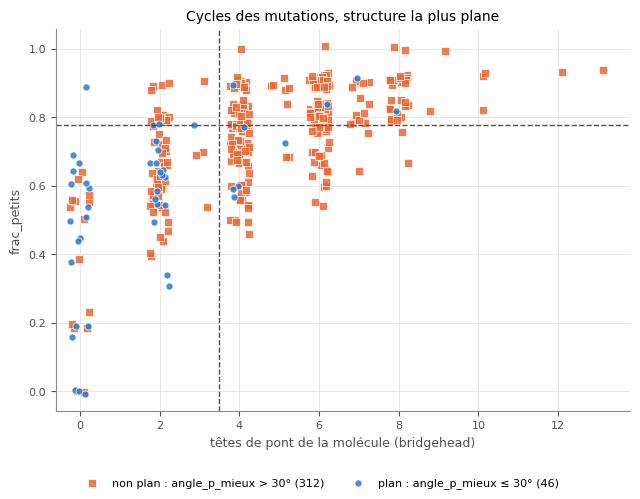

In [16]:
plan = CRITERES_PLAN["angle_p_mieux ≤ 30"]
meilleure = regles["angle_p_mieux ≤ 30"].iloc[0]
autre = next((c for c in meilleure.colonnes if c != "bridgehead"), "jonctions")
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(6.5, 5))
for est_plan, nom, couleur, marqueur in [(False, "non plan", COULEURS["refusée angle"], "s"),
                                         (True, "plan", COULEURS["acceptée"], "o")]:
    sel = mut_d[plan == est_plan]
    dx = rng.uniform(-0.25, 0.25, len(sel))
    dy = rng.uniform(-0.25, 0.25, len(sel)) * (1 if sel[autre].max() > 1 else 0.04)
    ax.scatter(sel.bridgehead + dx, sel[autre] + dy, s=26, marker=marqueur, color=couleur, edgecolors="white",
               linewidths=0.6, alpha=0.85, label=f"{nom} : angle_p_mieux {'≤' if est_plan else '>'} 30° ({len(sel)})")
if "bridgehead" in meilleure.colonnes and len(meilleure.colonnes) == 2:
    for c, s in zip(meilleure.colonnes, meilleure.seuils):
        (ax.axvline if c == "bridgehead" else ax.axhline)(s + (0.5 if c == "bridgehead" else 0), color="#52514e",
                                                          lw=1, ls="--")
else:
    ax.axvline(3.5, color="#52514e", lw=1, ls="--")
ax.set(xlabel="têtes de pont de la molécule (bridgehead)", ylabel=autre,
       title="Cycles des mutations, structure la plus plane")
ax.set_xlim(left=-0.6)
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=2)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(DOSSIER / "pontage.png", dpi=150)

### 10.6 Bilan

- **Le pontage prédit bien mieux la planéité que R4b.** Pour `angle_p_mieux` ≤ 30°, `bridgehead` donne 0,82
  [0,75 ; 0,88] contre 0,44 pour l'écart à 360° de R4b ; pour `rms_plan_mieux` ≤ 0,25 Å, 0,75 contre 0,52.
- **`spiro` ne sert à rien ici** : il vaut 0 sur tous les cycles des mutations, et `bridgehead_plus_spiro` revient à
  `bridgehead`.
- **Combiner n'apporte presque rien.** Régression logistique : 0,822 avec `bridgehead` seul, 0,847 au mieux avec trois
  descripteurs (`bridgehead` + `jonctions` + `frac_sp3_cycle`), 0,836 avec tous. Règles à deux seuils : la meilleure
  (`bridgehead` ≤ 3 et `frac_petits` ≤ 0,78) a 0,770 de précision équilibrée en validation croisée, contre 0,768 pour
  `bridgehead` ≤ 3 seul. Pour `rms_plan_mieux`, `bridgehead` ≤ 2 seul est en tête (0,686).
- **Règle la plus simple qui marche : refuser un grand cycle si la molécule a plus de 3 têtes de pont.** Sur ces
  cycles, elle garde 37 cycles plans sur 46 et élimine 234 non plans sur 312 (précision équilibrée 0,78, contre 0,50
  pour R4b). Elle laisse encore passer 78 cycles non plans.
- **Limites** : sur les références, elle refuserait la porphine et la phtalocyanine (8 têtes de pont, planes) et
  accepterait les [16], [20], [24]annulènes, le 18-couronne-6 et le cyclododécane (0 tête de pont, non plans). Elle
  complète R4b (refus des carbones s, macrocycles « de manuel ») plutôt qu'elle ne la remplace. Seuil choisi sur 46
  cycles plans seulement, et compté sur toute la molécule, pas seulement sur le grand cycle.
- Curiosité : pour `angle_p_mieux`, les cycles plans ont plutôt *plus* d'atomes saturés (`frac_sp3_cycle` : 0,38,
  sous 0,5 ; 0,50 pour `rms_plan_mieux`). Le refus « carbone s » de R4b n'est pas soutenu par ces données non plus.


### 10.7 Un seuil qui dépend de la taille du cycle ?

Variantes de `bridgehead` : têtes de pont situées sur le grand cycle (`bridgehead_cycle`, mêmes têtes de pont que
RDKit, recalculées atome par atome : extrémités des chemins partagés par deux cycles SSSR), rapportées au nombre
d'atomes du grand cycle ou de la molécule, et seuil qui varie avec la taille (`bridgehead` ≤ a + b × taille). Seuils
choisis et évalués en validation croisée comme en 10.4.

In [17]:
def tetes_de_pont(mol: Chem.Mol) -> set[int]:
    """Têtes de pont à la RDKit : extrémités des chemins (au moins 2 liaisons) partagés par deux cycles SSSR."""
    cycles_liaisons = [set(r) for r in mol.GetRingInfo().BondRings()]
    tetes = set()
    for i, j in combinations(range(len(cycles_liaisons)), 2):
        commun = cycles_liaisons[i] & cycles_liaisons[j]
        if len(commun) >= 2:
            bouts = pd.Series([a for b in commun for a in (mol.GetBondWithIdx(b).GetBeginAtomIdx(),
                                                         mol.GetBondWithIdx(b).GetEndAtomIdx())]).value_counts()
            tetes |= set(bouts.index[bouts == 1])
    return tetes


def descripteurs_taille(row) -> dict:
    mol = rp.rdkit_mol(*rp.decode(lot.loc[row.nom, "atomes"], lot.loc[row.nom, "liaisons"]))
    tetes = tetes_de_pont(mol)
    assert len(tetes) == num_bridgehead_atoms(mol)
    return {"bridgehead_cycle": len(tetes & set(map(int, row.cycle.split()))), "n_lourds": mol.GetNumHeavyAtoms()}


cyc = cyc.drop(columns=["bridgehead_cycle", "n_lourds"], errors="ignore")
cyc = pd.concat([cyc, cyc.apply(descripteurs_taille, axis=1, result_type="expand")], axis=1)
cyc["bridgehead_par_taille"] = cyc.bridgehead / cyc.taille
cyc["bridgehead_par_atome"] = cyc.bridgehead / cyc.n_lourds
mut_d = cyc[cyc.source == "mutation"].dropna(subset=["angle_p_mieux"])
CRITERES_PLAN = {"angle_p_mieux ≤ 30": mut_d.angle_p_mieux <= 30, "rms_plan_mieux ≤ 0.25": mut_d.rms_plan_mieux <= 0.25}


def regle_lineaire_cv(plan: pd.Series) -> tuple[float, tuple[float, float]]:
    """bridgehead ≤ a + b × taille : (a, b) choisis sur 4/5 des cycles, évalués sur le reste."""
    grille = [(a, b) for a in np.arange(0, 8.5, 0.5) for b in np.arange(-0.3, 0.31, 0.05)]
    bh, taille, y = mut_d.bridgehead.to_numpy(), mut_d.taille.to_numpy(), plan.to_numpy()

    def choisir(idx):
        return max(grille, key=lambda ab: precision_equilibree(bh[idx] <= ab[0] + ab[1] * taille[idx], y[idx]))

    tests = []
    for app, test in VALIDATION.split(bh, y):
        a, b = choisir(app)
        tests.append(precision_equilibree(bh[test] <= a + b * taille[test], y[test]))
    return np.mean(tests), choisir(np.arange(len(y)))


for critere, plan in CRITERES_PLAN.items():
    lignes = {}
    for d in ["bridgehead", "bridgehead_cycle", "bridgehead_par_taille", "bridgehead_par_atome"]:
        cv, seuils, _ = regle_cv((d,), plan)
        lignes[f"{d} ≤ {seuils[0]:.3g}"] = {"P(plan < non plan)": round(proba_plus_plan(mut_d.loc[plan, d], mut_d.loc[~plan, d]), 3),
                                          "précision équilibrée, validation croisée": round(cv, 3)}
    cv, (a, b) = regle_lineaire_cv(plan)
    lignes[f"bridgehead ≤ {a:.3g} {b:+.3g} × taille"] = {"P(plan < non plan)": np.nan,
                                                         "précision équilibrée, validation croisée": round(cv, 3)}
    print(critere)
    display(pd.DataFrame(lignes).T)

plan = CRITERES_PLAN["angle_p_mieux ≤ 30"]
display(mut_d.assign(plan=plan).groupby(mut_d.taille.clip(upper=16).rename("taille (16 : 16 et plus)")).apply(
    lambda d: pd.Series({"cycles": len(d), "plans": int(d.plan.sum()),
                         "bridgehead médian, plans": d.bridgehead[d.plan].median(),
                         "bridgehead médian, non plans": d.bridgehead[~d.plan].median()})))

angle_p_mieux ≤ 30


,P(plan < non plan),"précision équilibrée, validation croisée"
bridgehead ≤ 3,0.822,0.768
bridgehead_cycle ≤ 2,0.824,0.760
bridgehead_par_taille ≤ 0.222,0.814,0.767
bridgehead_par_atome ≤ 0.0667,0.838,0.754
bridgehead ≤ 3.5 -0.05 × taille,NaN,0.766


rms_plan_mieux ≤ 0.25


,P(plan < non plan),"précision équilibrée, validation croisée"
bridgehead ≤ 2,0.749,0.686
bridgehead_cycle ≤ 2,0.747,0.686
bridgehead_par_taille ≤ 0.222,0.718,0.688
bridgehead_par_atome ≤ 0.0851,0.773,0.669
bridgehead ≤ 7 -0.3 × taille,NaN,0.649


,cycles,plans,"bridgehead médian, plans","bridgehead médian, non plans"
taille (16 : 16 et plus),,,,
9,72.0,11.0,2.0,4.0
10,71.0,11.0,0.0,4.0
11,72.0,12.0,2.0,4.0
12,49.0,5.0,2.0,5.0
13,41.0,4.0,0.0,5.0
14,18.0,1.0,4.0,6.0
15,19.0,1.0,2.0,5.0
16,16.0,1.0,2.0,7.0


### 10.8 Comment le grand cycle traverse les petits cycles

R4b calcule l'angle à chaque atome de fusion en supposant le petit cycle à l'extérieur du grand. On décrit ici la
traversée elle-même, pour chaque petit cycle (8 atomes au plus) dont le grand cycle emprunte au moins une liaison :
- `traverses` : nombre de petits cycles traversés ; `pas_moyen` : part moyenne de leurs liaisons empruntées ;
- `para` : petits cycles traversés de part en part (au moins la moitié de leurs liaisons : para dans un benzène ;
  la porphine ne passe que par C–N–C, 2 liaisons sur 5) ; `ortho` : une seule liaison empruntée ;
- `systemes_traverses` : systèmes de petits cycles fusionnés traversés ; `max_par_systeme` : plus grand nombre de
  petits cycles d'un même système traversés (au moins 2 : le grand cycle passe à travers un système fusionné).

Et, à part, la déformation d'un dessin 2D RDKit (`Compute2DCoords`, polygones réguliers) : écart moyen des longueurs
de liaison à la médiane (`dev_liaison_moy`) et plus petite distance entre deux atomes non liés, en longueurs de
liaison (`contact_min`, petite = atomes qui se chevauchent). Idée : une molécule qui ne se dessine pas à plat sans
déformation ne peut pas être plane.

In [18]:
def systemes_fusionnes(petits: list[set[int]]) -> list[int]:
    """Numéro de système de chaque petit cycle (cycles qui partagent une liaison = même système)."""
    parent = list(range(len(petits)))

    def racine(i: int) -> int:
        while parent[i] != i:
            i = parent[i]
        return i

    for i, j in combinations(range(len(petits)), 2):
        if len(petits[i] & petits[j]) >= 2:
            parent[racine(j)] = racine(i)
    return [racine(i) for i in range(len(petits))]


def aretes(atomes: list[int]) -> set[frozenset]:
    return {frozenset((atomes[k], atomes[(k + 1) % len(atomes)])) for k in range(len(atomes))}


def descripteurs_fusion(row) -> dict:
    mol = rp.rdkit_mol(*rp.decode(lot.loc[row.nom, "atomes"], lot.loc[row.nom, "liaisons"]))
    grand = aretes(list(map(int, row.cycle.split())))
    petits = [list(r) for r in mol.GetRingInfo().AtomRings() if len(r) <= 8]
    pas, para, ortho, par_systeme = [], 0, 0, {}
    for petit, systeme in zip(petits, systemes_fusionnes([set(r) for r in petits])):
        k = len(aretes(petit) & grand)  # liaisons du petit cycle empruntées par le grand
        if k:
            pas.append(k / len(petit))
            para += k >= len(petit) / 2
            ortho += k == 1
            par_systeme[systeme] = par_systeme.get(systeme, 0) + 1

    dessin = Chem.Mol(mol)
    rdDepictor.Compute2DCoords(dessin)
    pos = dessin.GetConformer().GetPositions()[:, :2]
    liees = [(b.GetBeginAtomIdx(), b.GetEndAtomIdx()) for b in mol.GetBonds()]
    longueurs = np.array([np.linalg.norm(pos[i] - pos[j]) for i, j in liees])
    distances = np.linalg.norm(pos[:, None] - pos[None], axis=-1)
    np.fill_diagonal(distances, np.inf)
    for i, j in liees:
        distances[i, j] = distances[j, i] = np.inf
    return {"traverses": len(pas), "pas_moyen": np.mean(pas) if pas else 0.0, "para": para, "ortho": ortho,
            "systemes_traverses": len(par_systeme), "max_par_systeme": max(par_systeme.values(), default=0),
            "dev_liaison_moy": np.mean(np.abs(longueurs / np.median(longueurs) - 1)),
            "contact_min": distances.min() / np.median(longueurs)}


FUSION = ["traverses", "pas_moyen", "para", "ortho", "systemes_traverses", "max_par_systeme", "dev_liaison_moy",
          "contact_min"]
cyc = cyc.drop(columns=FUSION, errors="ignore")
cyc = pd.concat([cyc, cyc.apply(descripteurs_fusion, axis=1, result_type="expand")], axis=1)
mut_d = cyc[cyc.source == "mutation"].dropna(subset=["angle_p_mieux"])
CRITERES_PLAN = {"angle_p_mieux ≤ 30": mut_d.angle_p_mieux <= 30, "rms_plan_mieux ≤ 0.25": mut_d.rms_plan_mieux <= 0.25,
                 "angle_p_min_E ≤ 30": mut_d.angle_p_min_E <= 30}

display(pd.DataFrame({
    f"{critere} ({int(plan.sum())} plans)": {d: avec_intervalle(mut_d.loc[plan, d], mut_d.loc[~plan, d])
                                              for d in ["bridgehead"] + FUSION}
    for critere, plan in CRITERES_PLAN.items()}).rename_axis("P(plan < non plan)"))
display(cyc[cyc.source == "référence"].set_index("nom")[["verdict", "rms_plan_min_E", "bridgehead"] + FUSION].round(2))

,angle_p_mieux ≤ 30 (46 plans),rms_plan_mieux ≤ 0.25 (47 plans),angle_p_min_E ≤ 30 (8 plans)
P(plan < non plan),,,
bridgehead,0.82 [0.75 ; 0.88],0.75 [0.68 ; 0.82],0.94 [0.90 ; 0.97]
traverses,0.64 [0.55 ; 0.73],0.68 [0.59 ; 0.76],0.72 [0.48 ; 0.92]
pas_moyen,0.70 [0.62 ; 0.79],0.70 [0.61 ; 0.78],0.84 [0.68 ; 0.96]
para,0.62 [0.55 ; 0.69],0.64 [0.58 ; 0.70],0.75 [0.72 ; 0.77]
ortho,0.41 [0.32 ; 0.51],0.49 [0.40 ; 0.58],0.48 [0.21 ; 0.74]
systemes_traverses,0.61 [0.52 ; 0.69],0.65 [0.57 ; 0.72],0.67 [0.46 ; 0.85]
max_par_systeme,0.59 [0.50 ; 0.69],0.60 [0.51 ; 0.70],0.74 [0.51 ; 0.94]
dev_liaison_moy,0.64 [0.55 ; 0.73],0.62 [0.53 ; 0.70],0.61 [0.32 ; 0.87]
contact_min,0.36 [0.27 ; 0.46],0.46 [0.36 ; 0.55],0.17 [0.05 ; 0.34]


,verdict,rms_plan_min_E,bridgehead,traverses,pas_moyen,para,ortho,systemes_traverses,max_par_systeme,dev_liaison_moy,contact_min
nom,,,,,,,,,,,
[10]annulène,refusée angle,0.09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,1.90
[12]annulène,refusée angle,0.38,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,1.93
[14]annulène,acceptée,0.12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,1.95
[16]annulène,acceptée,0.45,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,1.96
[18]annulène,acceptée,0.11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,1.97
[20]annulène,acceptée,0.69,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,1.98
[22]annulène,acceptée,0.09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,1.98
[24]annulène,acceptée,0.72,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,1.98
porphine,acceptée,0.00,8.0,4.0,0.4,0.0,0.0,4.0,1.0,0.03,0.82


**Combinaisons** avec `bridgehead` (régression logistique, AUC en validation croisée, critère `angle_p_mieux` ≤ 30°).
`contact_min` est pris avec le signe moins (grand = plan).

In [19]:
plan = CRITERES_PLAN["angle_p_mieux ≤ 30"]
mut_d = mut_d.assign(contact_neg=-mut_d.contact_min)
A_COMBINER_FUSION = ["bridgehead", "traverses", "pas_moyen", "para", "systemes_traverses", "max_par_systeme",
                     "dev_liaison_moy", "contact_neg"]
scores = pd.Series({" + ".join(c): auc_cv(c, plan) for k in (1, 2, 3) for c in combinations(A_COMBINER_FUSION, k)})
display(scores.sort_values(ascending=False).head(8).round(3).to_frame("AUC"))
print(f"bridgehead seul : {scores['bridgehead']:.3f}")

,AUC
bridgehead + traverses + max_par_systeme,0.847
bridgehead + pas_moyen + systemes_traverses,0.845
bridgehead + systemes_traverses + max_par_systeme,0.844
bridgehead + systemes_traverses,0.843
bridgehead + systemes_traverses + dev_liaison_moy,0.841
bridgehead + systemes_traverses + contact_neg,0.840
bridgehead + traverses + systemes_traverses,0.840
bridgehead + para + systemes_traverses,0.839


bridgehead seul : 0.822


**Une exception pour les macrocycles de type porphyrine.** La porphine et la phtalocyanine ont 8 têtes de pont, mais
leur grand cycle ne passe qu'une fois par chaque système fusionné et jamais de part en part. Règle essayée : refuser
si `bridgehead` > 3, **sauf** si `para` = 0 et `max_par_systeme` ≤ 1. Les CPP (`para` > 0) restent refusés, et R4b les
refuse de toute façon par la somme des virages.

In [20]:
exception = (mut_d.para == 0) & (mut_d.max_par_systeme <= 1)
lignes = {}
for critere in ["angle_p_mieux ≤ 30", "rms_plan_mieux ≤ 0.25"]:
    plan = CRITERES_PLAN[critere]
    lignes[(critere, "R4b (acceptée)")] = bilan_filtre(mut_d.verdict == "acceptée", plan)
    lignes[(critere, "bridgehead ≤ 3")] = bilan_filtre(mut_d.bridgehead <= 3, plan)
    lignes[(critere, "bridgehead ≤ 3, sauf exception")] = bilan_filtre((mut_d.bridgehead <= 3) | exception, plan)
display(pd.DataFrame(lignes).T)
print("cycles des mutations sauvés par l'exception :", int(((mut_d.bridgehead > 3) & exception).sum()))

ref_d = cyc[cyc.source == "référence"].set_index("nom")
garde = (ref_d.bridgehead <= 3) | ((ref_d.para == 0) & (ref_d.max_par_systeme <= 1))
display(pd.DataFrame({"R4b": ref_d.verdict, "rms_plan_min_E": ref_d.rms_plan_min_E.round(2),
                      "bridgehead ≤ 3": np.where(ref_d.bridgehead <= 3, "gardé", "refusé"),
                      "avec l'exception": np.where(garde, "gardé", "refusé")}))

gardés plans gardés non plans éliminés précision équilibrée
angle_p_mieux ≤ 30    R4b (acceptée)                     48         6/46            270/312                  0.5
                      bridgehead ≤ 3                    115        37/46            234/312                 0.78
                      bridgehead ≤ 3, sauf exception    119        37/46            230/312                 0.77
rms_plan_mieux ≤ 0.25 R4b (acceptée)                     48         6/47            269/311                  0.5
                      bridgehead ≤ 3                    115        30/47            226/311                 0.68
                      bridgehead ≤ 3, sauf exception    119        31/47            223/311                 0.69

cycles des mutations sauvés par l'exception : 4


,R4b,rms_plan_min_E,bridgehead ≤ 3,avec l'exception
nom,,,,
[10]annulène,refusée angle,0.09,gardé,gardé
[12]annulène,refusée angle,0.38,gardé,gardé
[14]annulène,acceptée,0.12,gardé,gardé
[16]annulène,acceptée,0.45,gardé,gardé
[18]annulène,acceptée,0.11,gardé,gardé
[20]annulène,acceptée,0.69,gardé,gardé
[22]annulène,acceptée,0.09,gardé,gardé
[24]annulène,acceptée,0.72,gardé,gardé
porphine,acceptée,0.00,refusé,gardé


### 10.9 Bilan des essais 10.7 et 10.8

- **La taille n'aide pas.** Les cycles plans ont 0 à 2 têtes de pont en médiane quelle que soit leur taille (9 à 16
  atomes), les non plans 4 à 7 : le bon seuil ne bouge pas avec la taille. Ramener `bridgehead` au nombre d'atomes du
  cycle ou de la molécule, ou faire varier le seuil avec la taille, donne 0,75 à 0,77 de précision équilibrée en
  validation croisée, comme `bridgehead` ≤ 3 (0,77). Et 85 % des cycles ont 9 à 13 atomes, avec au plus un cycle plan
  par taille au-delà : un effet de la taille ne serait de toute façon pas mesurable ici. Diviser par la taille ne
  sépare pas non plus la porphine des CPP (0,5 tête de pont par atome du cycle pour les deux).
- **Les positions de fusion classent moins bien que `bridgehead`** (P de 0,59 à 0,70 contre 0,82), et les ajouter
  n'apporte presque rien (AUC 0,823 → 0,846). Le dessin 2D ne sépare pas mieux (0,58 à 0,64).
- **Mais elles permettent une exception utile.** « `bridgehead` > 3 refusé, sauf si le grand cycle ne traverse
  chaque système fusionné qu'une fois et jamais de part en part » garde la porphine et la phtalocyanine, et ne change
  que 4 cycles des mutations (aucun plan selon `angle_p_mieux`, un selon `rms_plan_mieux`) : précision
  équilibrée de 0,77 au lieu de 0,78 pour le premier critère, 0,69 au lieu de 0,68 pour le second.
- Reste non résolu : les [16], [20], [24]annulènes, l'éther-couronne et le cyclododécane, sans tête de pont ni fusion.
  Ceux-là relèvent de R4b (carbone s) ou d'une autre information (nombre d'électrons π).